# Olist Customer Segmentation with K-means

## Project Overview

**Business question:** How can customers be grouped according to their purchasing behavior to support differentiated marketing and customer retention strategies?

**Objective:** Develop a customer segmentation model using RFM (Recency, Frequency, and Monetary Value) features and the K-means clustering algorithm.

**Methodology:**
1. Prepare customer and order data.
2. Engineer customer-level RFM features.
3. Explore distributions and handle skewed variables.
4. Scale features and evaluate candidate cluster counts.
5. Train and interpret the K-means model.
6. Translate customer segments into actionable business recommendations.

**Tools:** Python, Pandas, Matplotlib, Scikit-learn.

**Dataset:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce).

**Limitation:** The analysis is based on historical marketplace transactions. Customer segments are exploratory and should not be interpreted as permanent customer characteristics.

In [1]:
# Install KaggleHub
!pip -q install kagglehub

# Download the Olist dataset
import kagglehub
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

# Load the required tables
orders = pd.read_csv(
    os.path.join(path, "olist_orders_dataset.csv")
)

customers = pd.read_csv(
    os.path.join(path, "olist_customers_dataset.csv")
)

items = pd.read_csv(
    os.path.join(path, "olist_order_items_dataset.csv")
)

print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Order items:", items.shape)


Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Orders: (99441, 8)
Customers: (99441, 5)
Order items: (112650, 7)


## 1. Data Preparation

### 1.1. Loading and Understanding the Data

The analysis uses three datasets: orders, customers, and order items.

These tables provide information about customer identifiers, purchase dates, order statuses, and item prices.

The first step is to inspect their structure, verify the relevant identifiers, and prepare the data for customer-level feature engineering.

**Initial validation criteria:**
- Purchase timestamps must be converted to datetime format.
- Customer and order identifiers must be checked for missing values.
- Only eligible transactions should be included in the segmentation analysis.

No records will be removed until the validation results have been reviewed.

In [2]:
# Inspect the structure of each dataset
for name, df in {
    "orders": orders,
    "customers": customers,
    "order_items": items
}.items():
    print(f"\n{name.upper()}")
    print("Shape:", df.shape)
    print("\nMissing values:")
    display(df.isna().sum().to_frame("missing_values"))
    print("\nSample records:")
    display(df.head(3))



ORDERS
Shape: (99441, 8)

Missing values:


,missing_values
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0



Sample records:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00



CUSTOMERS
Shape: (99441, 5)

Missing values:


...

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP



ORDER_ITEMS
Shape: (112650, 7)

Missing values:


,missing_values
order_id,0
order_item_id,0
product_id,0
seller_id,0
shipping_limit_date,0
price,0
freight_value,0



Sample records:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


### 1.2. Order Status and Transaction Eligibility

Before creating customer-level features, order statuses must be examined to determine which transactions are suitable for the analysis.

Missing delivery timestamps are not automatically treated as data quality errors, since they may be associated with canceled or otherwise undelivered orders.

**Analytical decision:** The initial RFM analysis will include delivered orders only. This provides a consistent basis for calculating purchase recency, order frequency, and merchandise value.

The distribution of order statuses will be reviewed before applying this filter.

In [3]:

# Review order status distribution
status_summary = (
    orders.groupby("order_status")
    .agg(
        total_orders=("order_id", "nunique"),
        unique_customers=("customer_id", "nunique")
    )
    .sort_values("total_orders", ascending=False)
    .reset_index()
)

status_summary["order_share_pct"] = (
    status_summary["total_orders"]
    / orders["order_id"].nunique()
    * 100
)

display(status_summary)


,order_status,total_orders,unique_customers,order_share_pct
0,delivered,96478,96478,97.020344
1,shipped,1107,1107,1.113223
2,canceled,625,625,0.628513
3,unavailable,609,609,0.612423
4,invoiced,314,314,0.315765
5,processing,301,301,0.302692
6,created,5,5,0.005028
7,approved,2,2,0.002011


In [4]:

# Convert purchase timestamps to datetime
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

# Inspect missing and invalid purchase timestamps
print(
    "Missing purchase timestamps:",
    orders["order_purchase_timestamp"].isna().sum()
)

# Check delivered orders with missing purchase timestamps
delivered_orders_check = orders[
    orders["order_status"] == "delivered"
].copy()

print(
    "Delivered orders:",
    len(delivered_orders_check)
)

print(
    "Delivered orders with missing purchase timestamps:",
    delivered_orders_check["order_purchase_timestamp"].isna().sum()
)


Missing purchase timestamps: 0
Delivered orders: 96478
Delivered orders with missing purchase timestamps: 0


### 1.3. RFM Feature Engineering

RFM analysis represents customer purchasing behavior through three features:

- **Recency:** Number of days since the customer's most recent purchase.
- **Frequency:** Number of distinct delivered orders associated with the customer.
- **Monetary Value:** Total merchandise value across the customer's delivered orders, excluding freight charges.

**Customer identifier:** The analysis uses `customer_unique_id` to group transactions at the customer level, since a customer may be associated with multiple order-specific customer identifiers.

**Reference date:** The day after the latest purchase timestamp among eligible delivered orders. This creates a consistent reference point for calculating recency.

Only delivered orders with valid purchase timestamps will be included in the initial RFM dataset.

In [5]:

# 1. Prepare eligible delivered orders
delivered_orders = orders.loc[
    (orders["order_status"] == "delivered")
    & orders["order_purchase_timestamp"].notna(),
    ["order_id", "customer_id", "order_purchase_timestamp"]
].copy()

# 2. Map order-specific customer IDs to unique customer IDs
customer_mapping = customers[
    ["customer_id", "customer_unique_id"]
].drop_duplicates()

delivered_orders = delivered_orders.merge(
    customer_mapping,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Check that every eligible order has a customer identifier
print(
    "Orders without customer_unique_id:",
    delivered_orders["customer_unique_id"].isna().sum()
)

# Keep only records with a valid unique customer identifier
delivered_orders = delivered_orders.dropna(
    subset=["customer_unique_id"]
).copy()

# 3. Aggregate merchandise value by order
delivered_order_ids = delivered_orders["order_id"]

delivered_items = items[
    items["order_id"].isin(delivered_order_ids)
].copy()

order_monetary = (
    delivered_items.groupby("order_id")["price"]
    .sum()
    .rename("order_merchandise_value")
    .reset_index()
)

# 4. Attach merchandise value to delivered orders
rfm_orders = delivered_orders.merge(
    order_monetary,
    on="order_id",
    how="left",
    validate="one_to_one"
)

rfm_orders["order_merchandise_value"] = (
    rfm_orders["order_merchandise_value"].fillna(0)
)

# 5. Define the reference date
reference_date = (
    rfm_orders["order_purchase_timestamp"].max().normalize()
    + pd.Timedelta(days=1)
)

# 6. Calculate customer-level RFM metrics
rfm = (
    rfm_orders.groupby("customer_unique_id")
    .agg(
        last_purchase=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary_value=("order_merchandise_value", "sum")
    )
    .reset_index()
)

rfm["recency_days"] = (
    reference_date - rfm["last_purchase"].dt.normalize()
).dt.days

# Keep the final modeling features
rfm = rfm[
    ["customer_unique_id", "recency_days",
     "frequency", "monetary_value"]
].copy()

print("Reference date:", reference_date.date())
print("Unique customers in RFM:", len(rfm))
print("Duplicate customer IDs:", rfm["customer_unique_id"].duplicated().sum())
print("Missing values in RFM:", rfm.isna().sum().sum())

display(rfm.head(10))


Orders without customer_unique_id: 0
Reference date: 2018-08-30
Unique customers in RFM: 93358
Duplicate customer IDs: 0
Missing values in RFM: 0


,customer_unique_id,recency_days,frequency,monetary_value
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90
2,0000f46a3911fa3c0805444483337064,538,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,322,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,289,1,180.00
5,0004bd2a26a76fe21f786e4fbd80607f,147,1,154.00
6,00050ab1314c0e55a6ca13cf7181fecf,132,1,27.99
7,00053a61a98854899e70ed204dd4bafe,183,1,382.00
8,0005e1862207bf6ccc02e4228effd9a0,544,1,135.00
9,0005ef4cd20d2893f0d9fbd94d3c0d97,171,1,104.90


## 2. Exploratory Data Analysis

### 2.1. RFM Feature Distribution

The RFM dataset contains 93,358 unique customers with no missing values or duplicate customer identifiers.

Before applying K-means, the distributions of recency, frequency, and monetary value will be examined to identify skewness, outliers, and differences in scale.

**Objectives:**
- Understand customer purchasing behavior.
- Measure the proportion of one-time versus repeat customers.
- Identify extreme values that may influence clustering.
- Determine whether feature transformations and scaling are needed before modeling.

In [6]:

# Summary statistics for RFM features
display(
    rfm[["recency_days", "frequency", "monetary_value"]]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .T
)

# Analyze the distribution of purchase frequency
frequency_summary = (
    rfm["frequency"]
    .value_counts()
    .sort_index()
    .rename_axis("number_of_orders")
    .reset_index(name="customers")
)

frequency_summary["customer_share_pct"] = (
    frequency_summary["customers"] / len(rfm) * 100
)

display(frequency_summary.head(15))

print(
    "One-time customers:",
    f"{(rfm['frequency'] == 1).mean() * 100:.2f}%"
)

print(
    "Repeat customers:",
    f"{(rfm['frequency'] > 1).mean() * 100:.2f}%"
)


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
recency_days,93358.0,238.478877,152.595054,1.00,115.00,219.00,347.0000,466.00,520.000,576.00,714.0
frequency,93358.0,1.033420,0.209097,1.00,1.00,1.00,1.0000,1.00,1.000,2.00,15.0
monetary_value,93358.0,141.621480,215.694014,0.85,47.65,89.73,154.7375,279.99,419.809,1004.99,13440.0


,number_of_orders,customers,customer_share_pct
0,1,90557,96.999722
1,2,2573,2.756057
2,3,181,0.193877
3,4,28,0.029992
4,5,9,0.009640
5,6,5,0.005356
6,7,3,0.003213
7,9,1,0.001071
8,15,1,0.001071


One-time customers: 97.00%
Repeat customers: 3.00%


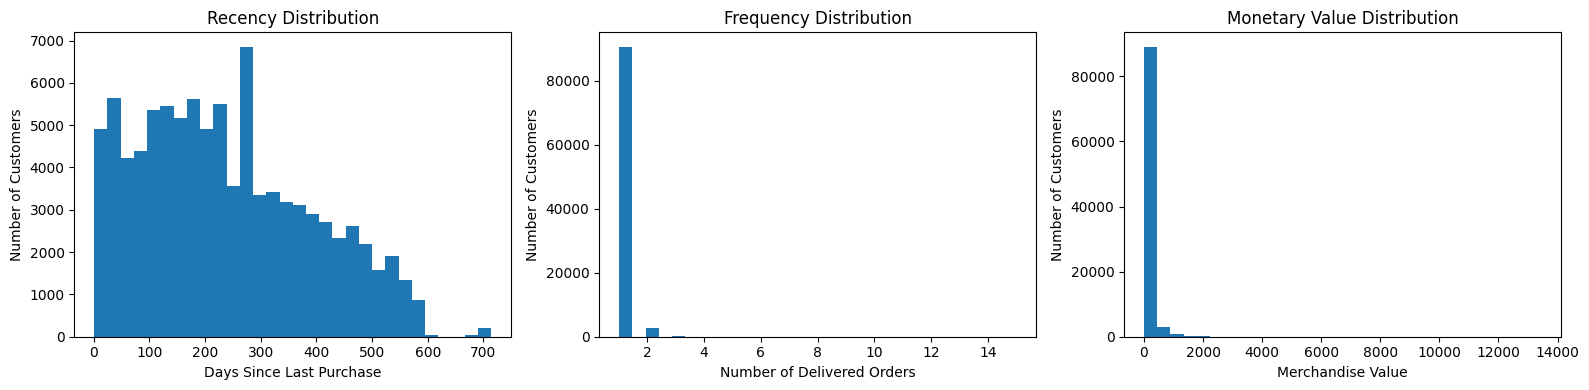

In [7]:

# Plot the distributions of RFM features
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(rfm["recency_days"], bins=30)
axes[0].set_title("Recency Distribution")
axes[0].set_xlabel("Days Since Last Purchase")
axes[0].set_ylabel("Number of Customers")

axes[1].hist(rfm["frequency"], bins=30)
axes[1].set_title("Frequency Distribution")
axes[1].set_xlabel("Number of Delivered Orders")
axes[1].set_ylabel("Number of Customers")

axes[2].hist(rfm["monetary_value"], bins=30)
axes[2].set_title("Monetary Value Distribution")
axes[2].set_xlabel("Merchandise Value")
axes[2].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()


### 2.2. Key Findings from RFM Exploration

The dataset contains 93,358 unique customers. Approximately 97% have one delivered order, while only 3% have made repeat purchases.

The median recency is 219 days, the median frequency is one order, and the median cumulative merchandise value is R$89.73.

The frequency and monetary value distributions are strongly right-skewed, indicating that a small number of customers have substantially higher purchase frequency or merchandise value than the majority.

**Modeling implications:**
- Apply a logarithmic transformation to reduce feature skewness.
- Scale the transformed features before applying K-means.
- Evaluate multiple cluster counts rather than selecting the number of clusters arbitrarily.
- Interpret the resulting segments in the context of the high proportion of one-time customers.

These findings motivate further preprocessing and model evaluation before assigning customer segments.

In [9]:
# Select RFM features for clustering
rfm_features = [
    "recency_days",
    "frequency",
    "monetary_value"
]

X = rfm[rfm_features].copy()

# Validate values before transformation
print("Negative values by feature:")
display((X < 0).sum().to_frame("negative_values"))

print("Zero values by feature:")
display((X == 0).sum().to_frame("zero_values"))

# Apply log1p transformation to reduce right skewness
X_log = X.copy()

for column in rfm_features:
    X_log[column] = np.log1p(X_log[column])

# Compare feature distributions before and after transformation
transformation_summary = pd.DataFrame({
    "original_skewness": X.skew(),
    "transformed_skewness": X_log.skew()
})

display(transformation_summary)


Negative values by feature:


,negative_values
recency_days,0
frequency,0
monetary_value,0


Zero values by feature:


,zero_values
recency_days,0
frequency,0
monetary_value,0


,original_skewness,transformed_skewness
recency_days,0.447487,-1.197087
frequency,11.095156,6.522068
monetary_value,9.746869,0.279788


## 3. K-means Model Development

### 3.1. Feature Scaling and Cluster Evaluation

The logarithmically transformed RFM features will be standardized before clustering so that differences in measurement scales do not dominate the distance calculations.

Candidate models with two to eight clusters will be evaluated using inertia and silhouette score.

The final cluster count will be selected by considering both quantitative metrics and business interpretability. No single metric will be treated as sufficient on its own.

In [10]:

# Standardize transformed features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

# Evaluate candidate cluster counts
evaluation_results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    evaluation_results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette_score": silhouette_score(
            X_scaled,
            labels,
            sample_size=10000,
            random_state=42
        )
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df)


,k,inertia,silhouette_score
0,2,190705.868364,0.711802
1,3,129573.259624,0.413478
2,4,83293.013487,0.391225
3,5,69099.075321,0.350438
4,6,58873.179393,0.350213
5,7,51836.681404,0.354903
6,8,46342.271920,0.337606


### 3.2. Selecting the Number of Clusters

K-means models with two to eight clusters were evaluated using inertia and silhouette score.

The two-cluster model achieved the highest silhouette score (**0.7118**), followed by the three-cluster model (**0.4135**).

This indicates that the two-cluster solution provides the strongest separation among the tested configurations according to this metric.

**Model selection decision:** The two-cluster solution will be examined first. Cluster sizes and customer-level RFM profiles will be reviewed to determine whether the resulting segments are meaningful and useful for business interpretation.

The silhouette score is a selection criterion, not proof that the resulting segments are commercially optimal.

In [11]:

# Train the selected two-cluster model
kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

rfm_clustered = rfm.copy()
rfm_clustered["cluster"] = kmeans_final.fit_predict(X_scaled)

# Summarize cluster sizes
cluster_sizes = (
    rfm_clustered.groupby("cluster")
    .agg(
        customers=("customer_unique_id", "count"),
        median_recency=("recency_days", "median"),
        median_frequency=("frequency", "median"),
        median_monetary_value=("monetary_value", "median"),
        mean_recency=("recency_days", "mean"),
        mean_frequency=("frequency", "mean"),
        mean_monetary_value=("monetary_value", "mean")
    )
    .reset_index()
)

cluster_sizes["customer_share_pct"] = (
    cluster_sizes["customers"]
    / len(rfm_clustered)
    * 100
)

display(cluster_sizes.round(2))


,cluster,customers,median_recency,median_frequency,median_monetary_value,mean_recency,mean_frequency,mean_monetary_value,customer_share_pct
0,0,90557,220.0,1.0,86.96,239.03,1.00,137.96,97.0
1,1,2801,200.0,2.0,182.10,220.81,2.11,260.05,3.0


### 3.3. Customer Segment Profiles

The two-cluster K-means model identified two distinct customer groups across 93,358 unique customers.

**Cluster 0 — One-time customers**
- Customers: 90,557 (97.0%).
- Median frequency: 1 delivered order.
- Median merchandise value: R$86.96.
- Median recency: 220 days.

This group represents the large majority of customers and is characterized by a single delivered purchase and lower cumulative merchandise value.

**Cluster 1 — Repeat customers**
- Customers: 2,801 (3.0%).
- Median frequency: 2 delivered orders.
- Median merchandise value: R$182.10.
- Median recency: 200 days.

This smaller group exhibits more frequent purchasing behavior and a higher median cumulative merchandise value. Its median recency is also 20 days lower, indicating more recent purchasing activity relative to Cluster 0.

**Business implications:**
- Customer retention initiatives could be explored to encourage a second purchase among one-time customers.
- Repeat customers may be suitable for further analysis of loyalty, purchase patterns, and customer lifetime value.
- Marketing investments should be evaluated using incremental conversion, retention, and profitability rather than cluster membership alone.

**Limitations:** These are descriptive profiles derived from historical transactions. The segments do not establish causal relationships or guarantee future purchasing behavior.

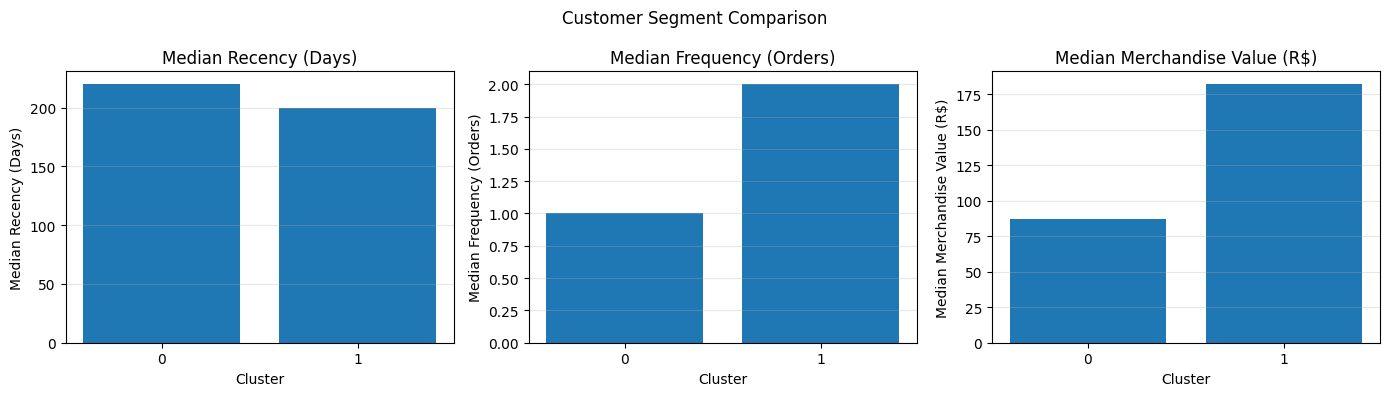

,cluster,customers,median_recency,median_frequency,median_monetary_value
0,0,90557,220.0,1.0,86.96
1,1,2801,200.0,2.0,182.10


In [12]:

# Compare customer segments using median RFM metrics
cluster_profiles = (
    rfm_clustered.groupby("cluster")
    .agg(
        customers=("customer_unique_id", "count"),
        median_recency=("recency_days", "median"),
        median_frequency=("frequency", "median"),
        median_monetary_value=("monetary_value", "median")
    )
    .reset_index()
)

# Plot the median metrics for each cluster
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

metrics = [
    ("median_recency", "Median Recency (Days)"),
    ("median_frequency", "Median Frequency (Orders)"),
    ("median_monetary_value", "Median Merchandise Value (R$)")
]

for ax, (column, title) in zip(axes, metrics):
    ax.bar(
        cluster_profiles["cluster"].astype(str),
        cluster_profiles[column]
    )
    ax.set_title(title)
    ax.set_xlabel("Cluster")
    ax.set_ylabel(title)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Customer Segment Comparison")
plt.tight_layout()
plt.show()

display(cluster_profiles.round(2))


In [13]:

# Compare purchase frequency across customer clusters
frequency_by_cluster = pd.crosstab(
    rfm_clustered["cluster"],
    rfm_clustered["frequency"],
    normalize="index"
) * 100

display(frequency_by_cluster.round(2))

# Calculate the percentage of repeat customers in each cluster
repeat_customer_share = (
    rfm_clustered.assign(
        is_repeat_customer=rfm_clustered["frequency"] > 1
    )
    .groupby("cluster")
    .agg(
        total_customers=("customer_unique_id", "count"),
        repeat_customers=("is_repeat_customer", "sum")
    )
    .reset_index()
)

repeat_customer_share["repeat_customer_pct"] = (
    repeat_customer_share["repeat_customers"]
    / repeat_customer_share["total_customers"]
    * 100
)

display(repeat_customer_share.round(2))


frequency,1,2,3,4,5,6,7,9,15
cluster,,,,,,,,,
0,100.0,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00
1,0.0,91.86,6.46,1.0,0.32,0.18,0.11,0.04,0.04


,cluster,total_customers,repeat_customers,repeat_customer_pct
0,0,90557,0,0.0
1,1,2801,2801,100.0


In [14]:

# Test an alternative model without purchase frequency
alternative_features = [
    "recency_days",
    "monetary_value"
]

X_alt = rfm[alternative_features].copy()

# Apply logarithmic transformations
X_alt_log = X_alt.apply(np.log1p)

# Standardize features
scaler_alt = StandardScaler()
X_alt_scaled = scaler_alt.fit_transform(X_alt_log)

# Evaluate two clusters
kmeans_alt = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

alt_labels = kmeans_alt.fit_predict(X_alt_scaled)

print(
    "Alternative silhouette score:",
    round(
        silhouette_score(
            X_alt_scaled,
            alt_labels,
            sample_size=10000,
            random_state=42
        ),
        4
    )
)

# Compare the resulting cluster profiles
rfm_alternative = rfm.copy()
rfm_alternative["cluster"] = alt_labels

display(
    rfm_alternative.groupby("cluster").agg(
        customers=("customer_unique_id", "count"),
        median_recency=("recency_days", "median"),
        median_frequency=("frequency", "median"),
        median_monetary_value=("monetary_value", "median")
    ).round(2)
)


Alternative silhouette score: 0.4041


,customers,median_recency,median_frequency,median_monetary_value
cluster,,,,
0,73231,272.0,1.0,89.5
1,20127,45.0,1.0,89.9


In [15]:

# Compare detailed customer profiles in the alternative model
alternative_profiles = (
    rfm_alternative.groupby("cluster")
    .agg(
        customers=("customer_unique_id", "count"),
        median_recency=("recency_days", "median"),
        mean_recency=("recency_days", "mean"),
        median_monetary=("monetary_value", "median"),
        mean_monetary=("monetary_value", "mean"),
        p90_monetary=("monetary_value", lambda x: x.quantile(0.90)),
        repeat_customer_pct=(
            "frequency",
            lambda x: (x > 1).mean() * 100
        )
    )
    .reset_index()
)

alternative_profiles["customer_share_pct"] = (
    alternative_profiles["customers"]
    / len(rfm_alternative)
    * 100
)

display(alternative_profiles.round(2))


,cluster,customers,median_recency,mean_recency,median_monetary,mean_monetary,p90_monetary,repeat_customer_pct,customer_share_pct
0,0,73231,272.0,290.35,89.5,140.84,279.99,2.89,78.44
1,1,20127,45.0,49.73,89.9,144.48,284.28,3.40,21.56


### 3.4. Cluster Composition and Model Comparison

The frequency distribution confirms a clear distinction between the two-cluster RFM solution:

- **Cluster 0:** All 90,557 customers (100%) have exactly one delivered order.
- **Cluster 1:** All 2,801 customers (100%) have made repeat purchases. Within this group, 91.86% have two orders and 6.46% have three orders.

The three-feature model therefore primarily separates one-time customers from repeat customers. Its silhouette score was 0.7118.

The alternative model, which uses recency and monetary value but excludes frequency, achieved a silhouette score of 0.4041. It separated customers mainly by recency: the clusters had median recency values of 272 and 45 days, while their median merchandise values were nearly identical (R$89.50 and R$89.90).

**Modeling decision:** Treat the two-feature model as the primary exploratory segmentation when the business objective is to distinguish customers with more recent versus less recent purchases. Retain the three-feature model as a comparison focused on one-time versus repeat purchasing behavior.

The silhouette scores should not be compared as if they were calculated in the same feature space. Neither model establishes future customer behavior or campaign effectiveness.


## 4. Executive Summary and Business Recommendations

### Key Findings

The alternative K-means model used recency and monetary value to segment 93,358 unique customers into two groups.

- **Cluster 0 — Less Recently Active:** 73,231 customers (78.44%), with a median recency of 272 days.
- **Cluster 1 — More Recently Active:** 20,127 customers (21.56%), with a median recency of 45 days.

The two clusters have similar monetary value distributions. Median merchandise value was R$89.50 for Cluster 0 and R$89.90 for Cluster 1. The 90th-percentile values were also similar.

The repeat-customer share was 2.89% in Cluster 0 and 3.40% in Cluster 1. This difference is descriptive and does not establish a meaningful difference in future retention.

### Business Recommendations

1. **Reactivation analysis:** Investigate whether customers with longer purchase recency respond to targeted reactivation campaigns.
2. **Retention analysis:** Study whether recently active customers make another purchase within a defined observation window.
3. **Campaign evaluation:** Measure incremental repeat purchases and merchandise value to determine whether these strategies generate business value.

### Model Assessment and Decision

The two-feature model (recency and monetary value) is the primary exploratory segmentation for recency-based business questions. It separates customers with median recency of 272 days and 45 days, while their median merchandise values are nearly identical (R$89.50 and R$89.90). Its silhouette score was 0.4041.

The three-feature RFM model achieved a silhouette score of 0.7118, but its clusters perfectly separated one-time customers from repeat customers in this dataset. It is retained as a comparison model for purchase-frequency analysis.

The silhouette scores should not be directly compared because the models use different feature spaces. The final choice depends on the business objective, not on the score alone.

### Limitations

- The analysis is based on historical transactions ending in 2018.
- Merchandise value excludes freight charges, product costs, and profit.
- Customer segments describe past behavior and do not predict future purchases.
- Campaign recommendations require validation through experiments or subsequent behavioral data.

### Conclusion

This project demonstrates an end-to-end customer segmentation workflow using Python, RFM feature engineering, logarithmic transformation, feature scaling, K-means clustering, and silhouette-based model evaluation.

The results provide an exploratory basis for customer reactivation and retention analysis. Further validation is required before using the segments to guide actual marketing investments.